In [ ]:
import os
import json
for f in os.listdir("/content"):
  if f.endswith(".zip"):
    print(f)

disequil_spectra_output_8k.zip
freckll_survey_output.zip
ace_equilibrium_spectra_output.zip
free_chem_spectra_output.zip


In [ ]:
!unzip -q /content/ace_equilibrium_spectra_output.zip -d /content/ace_equilibrium_spectra_output
!unzip -q /content/disequil_spectra_output_8k.zip -d /content/disequil_spectra_output_8k
!unzip -q /content/free_chem_spectra_output.zip -d /content/free_chem_spectra_output

In [ ]:
import glob
import numpy as np
ace = glob.glob("/content/ace_equilibrium_spectra_output/**/spec_*.npy",recursive=True)
print("ACE: ",len(ace))
disequi = glob.glob("/content/disequil_spectra_output_8k/**/spec_*.npy",recursive=True)
print("Disequi: ",len(disequi))
free = glob.glob("/content/free_chem_spectra_output/**/spec_*.npy", recursive=True)
print("Free: ", len(free))

ACE:  8426
Disequi:  8426
Free:  9972


In [ ]:
print(ace[0])
print(disequi[0])
print(free[0])

/content/ace_equilibrium_spectra_output/ace_equilibrium_spectra_output/spec_06915.npy
/content/disequil_spectra_output_8k/disequil_spectra_output_8k/spec_06915.npy
/content/free_chem_spectra_output/free_chem_spectra_output/spec_06915.npy


In [ ]:
ace_spectra = np.array([np.load(p) for p in sorted(ace)])
print("Equi",ace_spectra.shape)
disequi_spectra = np.array([np.load(d) for d in sorted(disequi)])
print("Disequi", disequi_spectra.shape)
free_spectra = np.array([np.load(f) for f in sorted(free)])
print("Free:", free_spectra.shape)
print(ace_spectra[0])
print(disequi_spectra[0])
print(free_spectra[0])

Equi (8426, 52)
Disequi (8426, 52)
Free: (9972, 52)
[0.02313491 0.02311165 0.02325903 0.02337712 0.02339113 0.02356175
 0.02353939 0.02349246 0.02358825 0.02358229 0.02359797 0.02358795
 0.02358023 0.02355358 0.02353335 0.02349941 0.02349287 0.02351231
 0.02353109 0.02357084 0.02361164 0.02364457 0.02365619 0.02365524
 0.02364046 0.0236535  0.02367442 0.02368051 0.02367376 0.02368692
 0.02368061 0.02367781 0.02367167 0.02366028 0.0236499  0.02363757
 0.02361627 0.02360577 0.02359023 0.0235744  0.02355541 0.02353057
 0.02353133 0.02358875 0.02363113 0.02363789 0.02365711 0.02365542
 0.023639   0.0236443  0.02370113 0.02369012]
[0.02313491 0.02311169 0.02325944 0.02337827 0.02339233 0.02356649
 0.02354311 0.02349537 0.02359426 0.02358801 0.02360421 0.02359376
 0.02358547 0.02355771 0.02353682 0.02350206 0.02349548 0.02351497
 0.02353448 0.02357547 0.02361835 0.02365315 0.023666   0.02366455
 0.02364896 0.02366342 0.02368565 0.02369187 0.02368453 0.02369863
 0.02369184 0.02368888 0.023682

In [ ]:
import numpy as np, os

SEED = 42
N_PLANETS = 10000
rng = np.random.default_rng(SEED)
Teq   = rng.uniform(300.0, 3000.0, N_PLANETS)
Rp    = rng.uniform(0.1, 2.0, N_PLANETS)
Mp    = rng.uniform(0.1, 5.0, N_PLANETS)
Rstar = rng.uniform(0.5, 2.0, N_PLANETS)
log_abund = rng.uniform(-9.0, -3.0, size=(N_PLANETS, 5))

# match each saved spectrum to its Teq by filename index
free_sorted = sorted(free)
free_spectra = np.array([np.load(f) for f in free_sorted])
free_T = np.array([
    Teq[int(os.path.basename(f).split("_")[1].split(".")[0])]
    for f in free_sorted
])
print("free_spectra:", free_spectra.shape)
print("free_T:", free_T.shape, "range:", free_T.min(), "-", free_T.max())

free_spectra: (9972, 52)
free_T: (9972,) range: 300.8489330390348 - 2999.9379551277743


In [ ]:
!unzip -q /content/freckll_survey_output.zip -d /content/freckll_survey_output

In [ ]:
found = glob.glob("/content/freckll_survey_output/**/params.json", recursive=True)
print("params.json files found:", len(found))
if found:
    print("example:", found[0])

params.json files found: 8426
example: /content/freckll_survey_output/freckll_survey_output/planet_5554/params.json


In [ ]:
planet_dirs = glob.glob("/content/freckll_survey_output/freckll_survey_output/planet_*")
# show a few folder names
for p in sorted(planet_dirs)[:5]:
    print(os.path.basename(p))

planet_0000
planet_0001
planet_0002
planet_0003
planet_0005


In [ ]:
# the SAME sorted folder list the notebook used
planet_dirs_sorted = sorted(glob.glob("/content/freckll_survey_output/freckll_survey_output/planet_*"))
print("Number of folders:", len(planet_dirs_sorted))

# temperature by POSITION (index i), matching spec_{i}.npy
import json
temps_by_position = []
for pdir in planet_dirs_sorted:
    with open(f"{pdir}/params.json") as f:
        temps_by_position.append(json.load(f)["Teq_K"])
temps_by_position = np.array(temps_by_position)
print("temps_by_position shape:", temps_by_position.shape)

Number of folders: 8426
temps_by_position shape: (8426,)


In [ ]:
import os

ace_sorted = sorted(ace)   # same order as ace_spectra was built

ace_T = []
for path in ace_sorted:
    # the number in the filename IS the position index
    pos = int(os.path.basename(path).split("_")[1].split(".")[0])
    ace_T.append(temps_by_position[pos])

ace_T = np.array(ace_T)
print("ace_T shape:", ace_T.shape)
print("first 5 temps:", ace_T[:5])

ace_T shape: (8426,)
first 5 temps: [2389.6813311  1484.97178733 2618.21438376 2182.89367846 2934.18034942]


In [ ]:
disequi_sorted = sorted(disequi)   # same order as disequi_spectra was built

disequi_T = []
for path in disequi_sorted:
    pos = int(os.path.basename(path).split("_")[1].split(".")[0])
    disequi_T.append(temps_by_position[pos])

disequi_T = np.array(disequi_T)
print("disequi_T shape:", disequi_T.shape)
print("first 5 temps:", disequi_T[:5])

disequi_T shape: (8426,)
first 5 temps: [2389.6813311  1484.97178733 2618.21438376 2182.89367846 2934.18034942]


In [ ]:
print("ACE T:     ", ace_T.min(), "-", ace_T.max())
print("Disequi T: ", disequi_T.min(), "-", disequi_T.max())
print("Free T:    ", free_T.min(), "-", free_T.max())

ACE T:      437.5839685460138 - 2999.9379551277743
Disequi T:  437.5839685460138 - 2999.9379551277743
Free T:     300.8489330390348 - 2999.9379551277743


In [ ]:
temp_floor = ace_T.min()
print("Temperature floor:", temp_floor)

Temperature floor: 437.5839685460138


In [ ]:
keep_mask = free_T >= temp_floor
free_spectra_trimmed  = free_spectra[keep_mask]
free_T_trimmed = free_T[keep_mask]
print("Free before:", free_spectra.shape[0])
print("Free after: ", free_spectra_trimmed.shape[0])
print("New free T range:", free_T_trimmed.min(), "-", free_T_trimmed.max())

Free before: 9972
Free after:  9452
New free T range: 437.5839685460138 - 2999.9379551277743


In [ ]:
n_target = ace_spectra.shape[0]
rng = np.random.default_rng(42)
pick = rng.choice(free_spectra_trimmed.shape[0], size=n_target, replace=False)
free_spectra_final = free_spectra_trimmed[pick]
free_T_final = free_T_trimmed[pick]

print("Free final spectra:", free_spectra_final.shape)
print("Free final T range:", free_T_final.min(), "-", free_T_final.max())

ace_spectra_final = ace_spectra
ace_T_final = ace_T

disequi_spectra_final = disequi_spectra
disequi_T_final = disequi_T

print("ACE final:    ", ace_spectra_final.shape)
print("Disequi final:", disequi_spectra_final.shape)
print("Free final:   ", free_spectra_final.shape)

Free final spectra: (8426, 52)
Free final T range: 437.5839685460138 - 2999.9379551277743
ACE final:     (8426, 52)
Disequi final: (8426, 52)
Free final:    (8426, 52)


In [ ]:
X = np.vstack([ace_spectra_final, disequi_spectra_final, free_spectra_final])
T = np.concatenate([ace_T_final, disequi_T_final, free_T_final])
labels = np.array([0]*8426+[1]*8426+[2]*8426)
print("X shape:", X.shape)
print("T shape:", T.shape)
print("labels shape:", labels.shape)

X shape: (25278, 52)
T shape: (25278,)
labels shape: (25278,)


In [ ]:
order = rng.permutation(X.shape[0])
X = X[order]
T = T[order]
labels = labels[order]

print("Shuffled labels:", labels[:10])

Shuffled labels: [2 2 1 0 0 1 0 1 2 1]


In [ ]:
np.savez("chem_regime_spectra_v2.npz", X = X, labels=labels, T= T)
print("All spectras dataset saved!")

All spectras dataset saved!


### 0 -> Equilibrium
### 1 -> Disequilibrium
### 2 -> Free

In [24]:
# ============================================================
# RESTART POINT — run this after a kernel restart to skip Phase 0
# Loads the saved dataset + redoes all imports + normalization
# ============================================================

# --- all imports the downstream cells use ---
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, confusion_matrix, silhouette_score
import hdbscan
import umap
import plotly.express as px

# --- load the saved dataset (choose which one) ---
data = np.load("chem_regime_spectra_v2.npz")        # or "chem_regime_spectra_newfree.npz"
X = data["X"]
labels = data["labels"]
T = data["T"]
print("Loaded:", X.shape, "| labels:", np.bincount(labels), "| T range:", T_all.min(), "-", T_all.max())

# --- redo Phase 1 normalization (needed for all downstream) ---
# per-spectrum z-score
X_zscore = (X - X.mean(axis=1, keepdims=True)) / (X.std(axis=1, keepdims=True) + 1e-8)
# StandardScaler on top (Variation A input)
X_scaled = StandardScaler().fit_transform(X_zscore)
print("X_zscore:", X_zscore.shape, "| X_scaled:", X_scaled.shape)

# --- convenience: class colors/names used in plots ---
colors = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}
names = {0: "equilibrium", 1: "disequilibrium", 2: "free"}

print("\nReady — X_zscore (Variation B) and X_scaled (Variation A) rebuilt.")
print("You can now run any Phase 2-5 / UMAP / KPCA cell directly.")

Loaded: (25278, 52) | labels: [8426 8426 8426] | T range: 437.5839685460138 - 2999.9379551277743
X_zscore: (25278, 52) | X_scaled: (25278, 52)

Ready — X_zscore (Variation B) and X_scaled (Variation A) rebuilt.
You can now run any Phase 2-5 / UMAP / KPCA cell directly.


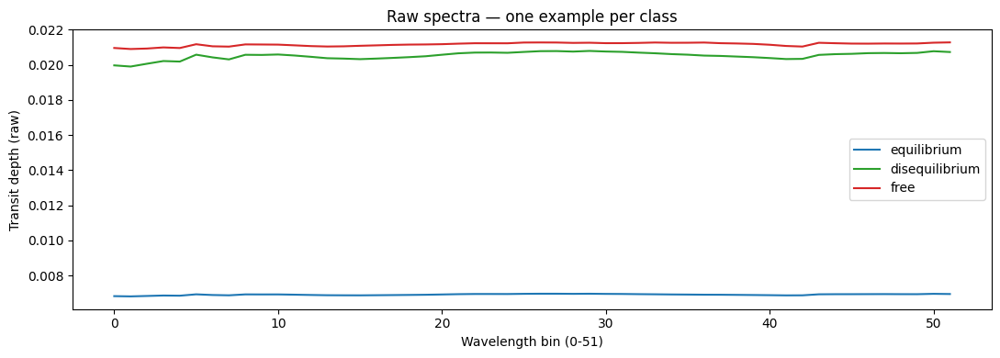

In [25]:
import matplotlib.pyplot as plt

i_equi = np.where(labels == 0)[0][0]
i_diseq = np.where(labels == 1)[0][0]
i_free = np.where(labels == 2)[0][0]

plt.figure(figsize=(11, 4))
plt.plot(X[i_equi], label="equilibrium", color="tab:blue")
plt.plot(X[i_diseq], label="disequilibrium", color="tab:green")
plt.plot(X[i_free], label="free", color="tab:red")
plt.xlabel("Wavelength bin (0-51)")
plt.ylabel("Transit depth (raw)")
plt.title("Raw spectra — one example per class")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
X_zscore = (X - X.mean(axis = 1, keepdims=True))/(X.std(axis = 1, keepdims=True) + 1e-8)

print("Z-score norm X shape:", X_zscore.shape)
print("Row 0 mean (should be ~0):", X_zscore[0].mean())
print("Row 0 std (should be ~1):", X_zscore[0].std())

Z-score norm X shape: (25278, 52)
Row 0 mean (should be ~0): -1.873287849627139e-14
Row 0 std (should be ~1): 0.999899788438266


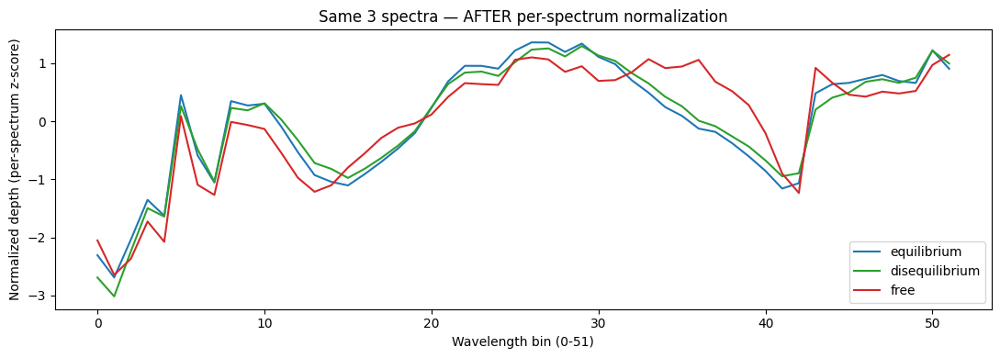

In [27]:
plt.figure(figsize=(11, 4))
plt.plot(X_zscore[i_equi], label="equilibrium", color="tab:blue")
plt.plot(X_zscore[i_diseq], label="disequilibrium", color="tab:green")
plt.plot(X_zscore[i_free], label="free", color="tab:red")
plt.xlabel("Wavelength bin (0-51)")
plt.ylabel("Normalized depth (per-spectrum z-score)")
plt.title("Same 3 spectra — AFTER per-spectrum normalization")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_zscore)

print("X_scaled shape:", X_scaled.shape)
print("Column 0 mean (should be ~0):", X_scaled[:, 0].mean())
print("Column 0 std (should be ~1):", X_scaled[:, 0].std())

X_scaled shape: (25278, 52)
Column 0 mean (should be ~0): 9.825267341466312e-15
Column 0 std (should be ~1): 0.9999999999999991


# Variation A - with StandardScaler

In [29]:
from sklearn.decomposition import PCA
import numpy as np

pca_A = PCA(n_components=6)
X_pca_A = pca_A.fit_transform(X_scaled)

print("X_pca_A shape:", X_pca_A.shape)

evr = pca_A.explained_variance_ratio_
print("Explained variance per component:", evr)
print()
print("Cumulative (running total):")
for k in range(6):
    print(f"  {k+1} components: {evr[:k+1].sum():.4f}")

X_pca_A shape: (25278, 6)
Explained variance per component: [0.44952812 0.17952775 0.10856953 0.08256874 0.06015048 0.04919607]

Cumulative (running total):
  1 components: 0.4495
  2 components: 0.6291
  3 components: 0.7376
  4 components: 0.8202
  5 components: 0.8803
  6 components: 0.9295


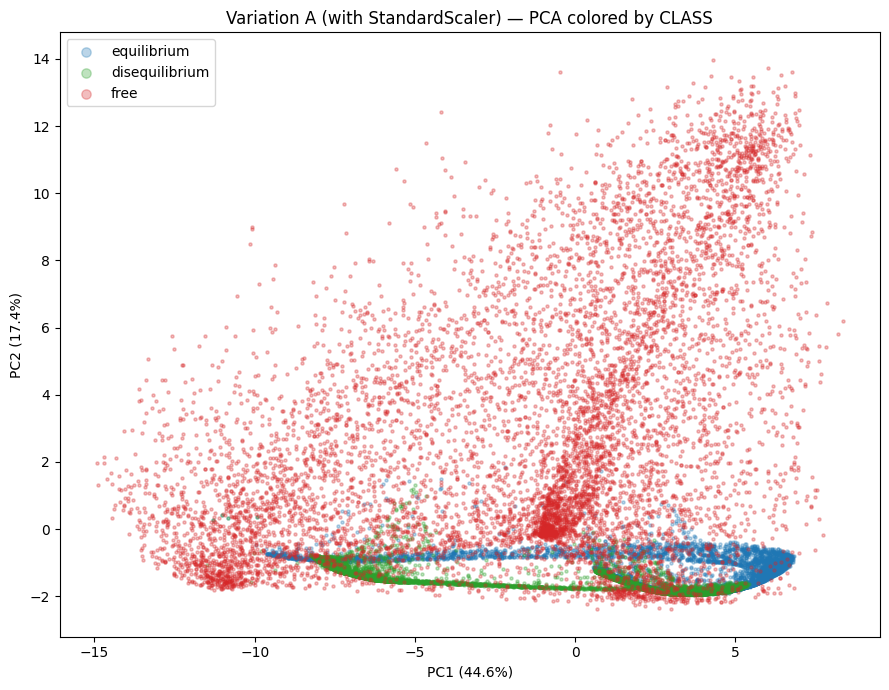

In [30]:
import matplotlib.pyplot as plt

colors = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}
names = {0: "equilibrium", 1: "disequilibrium", 2: "free"}

plt.figure(figsize=(9, 7))
for cls in [0, 1, 2]:
    mask = labels == cls
    plt.scatter(X_pca_A[mask, 0], X_pca_A[mask, 1],
                s=5, alpha=0.3, color=colors[cls], label=names[cls])

plt.xlabel("PC1 (44.6%)")
plt.ylabel("PC2 (17.4%)")
plt.title("Variation A (with StandardScaler) — PCA colored by CLASS")
plt.legend(markerscale=3)
plt.tight_layout()
plt.show()

In [31]:
import plotly.express as px
import pandas as pd

# build a small dataframe for plotly
df = pd.DataFrame({
    "PC1": X_pca_A[:, 0],
    "PC2": X_pca_A[:, 1],
    "PC3": X_pca_A[:, 2],
    "class": [names[l] for l in labels]
})

fig = px.scatter_3d(df, x="PC1", y="PC2", z="PC3",
                    color="class",
                    color_discrete_map={"equilibrium": "blue",
                                        "disequilibrium": "green",
                                        "free": "red"},
                    opacity=0.4,
                    title="Variation A — interactive 3D PCA")
fig.update_traces(marker=dict(size=2))
fig.show()

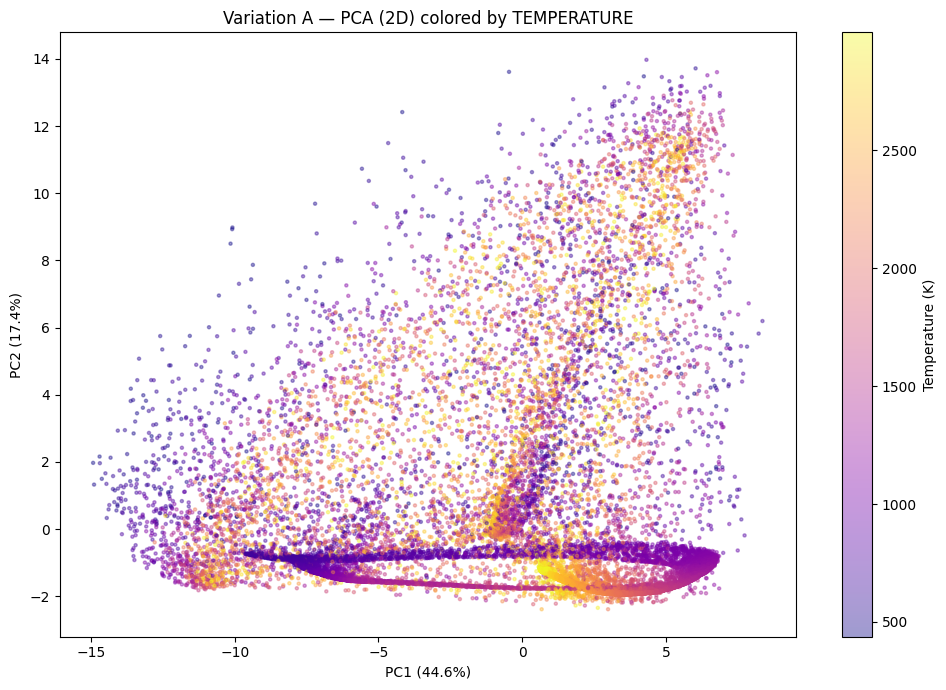

In [32]:
plt.figure(figsize=(10, 7))
sc = plt.scatter(X_pca_A[:, 0], X_pca_A[:, 1],
                 c=T, cmap="plasma", s=5, alpha=0.4)
plt.colorbar(sc, label="Temperature (K)")
plt.xlabel("PC1 (44.6%)")
plt.ylabel("PC2 (17.4%)")
plt.title("Variation A — PCA (2D) colored by TEMPERATURE")
plt.tight_layout()
plt.show()

In [33]:
df["temperature"] = T

fig = px.scatter_3d(df, x="PC1", y="PC2", z="PC3",
                    color="temperature",
                    color_continuous_scale="plasma",
                    opacity=0.4,
                    title="Variation A — interactive 3D PCA colored by TEMPERATURE")
fig.update_traces(marker=dict(size=2))
fig.show()

In [34]:
from sklearn.cluster import KMeans
x_for_clustering = X_pca_A

kmeans = KMeans(n_clusters=3, random_state=42,n_init = 10)
clusters = kmeans.fit_predict(x_for_clustering)

print("Cluster shape", clusters.shape)
print("Cluster sizes:", np.bincount(clusters))

Cluster shape (25278,)
Cluster sizes: [ 2767  6691 15820]


In [35]:
from sklearn.metrics import adjusted_rand_score,confusion_matrix
ari = adjusted_rand_score(labels, clusters)
print("Adjusted Rand Index:", ari)

cm = confusion_matrix(labels, clusters)
print("\nConfusion matrix (rows = true class, cols = cluster):")
print("            cluster0  cluster1  cluster2")
for i, name in enumerate(["equilibrium ", "disequilib. ", "free        "]):
    print(name, cm[i])

Adjusted Rand Index: 0.13023839910496984

Confusion matrix (rows = true class, cols = cluster):
            cluster0  cluster1  cluster2
equilibrium  [   0  775 7651]
disequilib.  [   0 2984 5442]
free         [2767 2932 2727]


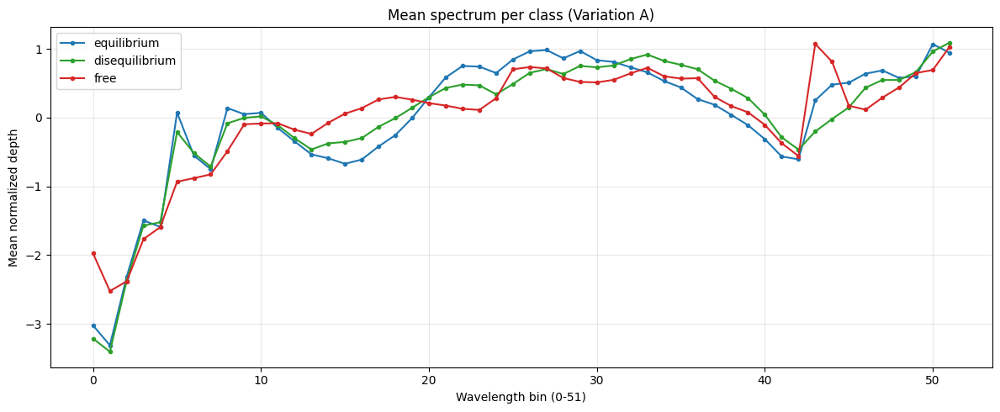

In [36]:
import matplotlib.pyplot as plt

# average the per-spectrum-normalized spectra within each class
mean_equi = X_zscore[labels == 0].mean(axis=0)
mean_diseq = X_zscore[labels == 1].mean(axis=0)
mean_free = X_zscore[labels == 2].mean(axis=0)

plt.figure(figsize=(12, 5))
plt.plot(mean_equi, label="equilibrium", color="tab:blue", marker="o", markersize=3)
plt.plot(mean_diseq, label="disequilibrium", color="tab:green", marker="o", markersize=3)
plt.plot(mean_free, label="free", color="tab:red", marker="o", markersize=3)
plt.xlabel("Wavelength bin (0-51)")
plt.ylabel("Mean normalized depth")
plt.title("Mean spectrum per class (Variation A)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
wl_binned = np.load("wl_binned.npy")
print("wl_binned shape:", wl_binned.shape)
print("\nBin -> Wavelength (microns):")
for b in [5, 6, 7, 8, 13, 15, 17, 19, 42, 43, 44, 45, 46]:
    print(f"  bin {b:2d}: {wl_binned[b]:.3f} um")

wl_binned shape: (52,)

Bin -> Wavelength (microns):
  bin  5: 1.406 um
  bin  6: 1.550 um
  bin  7: 1.708 um
  bin  8: 1.884 um
  bin 13: 2.133 um
  bin 15: 2.219 um
  bin 17: 2.310 um
  bin 19: 2.403 um
  bin 42: 4.032 um
  bin 43: 4.305 um
  bin 44: 4.597 um
  bin 45: 4.909 um
  bin 46: 5.242 um


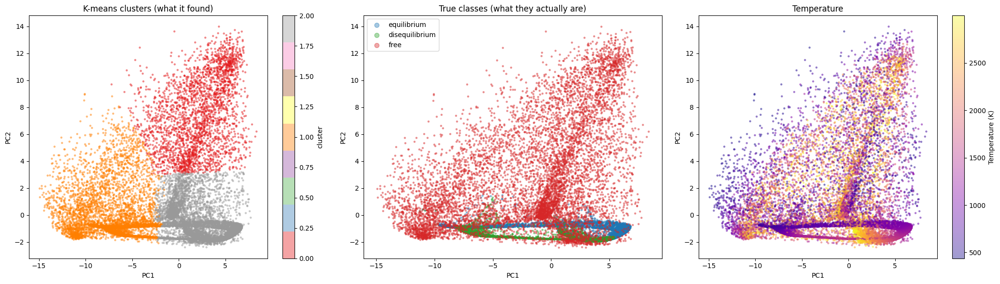

In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# --- Panel 1: colored by K-MEANS CLUSTER ---
sc0 = axes[0].scatter(X_pca_A[:, 0], X_pca_A[:, 1],
                      c=clusters, cmap="Set1", s=5, alpha=0.4)
axes[0].set_title("K-means clusters (what it found)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
plt.colorbar(sc0, ax=axes[0], label="cluster")

# --- Panel 2: colored by TRUE CLASS ---
colors = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}
names = {0: "equilibrium", 1: "disequilibrium", 2: "free"}
for cls in [0, 1, 2]:
    m = labels == cls
    axes[1].scatter(X_pca_A[m, 0], X_pca_A[m, 1],
                    s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[1].set_title("True classes (what they actually are)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].legend(markerscale=3)

# --- Panel 3: colored by TEMPERATURE ---
sc2 = axes[2].scatter(X_pca_A[:, 0], X_pca_A[:, 1],
                      c=T, cmap="plasma", s=5, alpha=0.4)
axes[2].set_title("Temperature")
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2")
plt.colorbar(sc2, ax=axes[2], label="Temperature (K)")

plt.tight_layout()
plt.savefig("variationA_cluster_comparison.png", dpi=150)
plt.show()

In [40]:
from sklearn.metrics import silhouette_score
sample_idx = np.random.default_rng(42).choice(len(clusters), 5000, replace=False)

sil = silhouette_score(X_pca_A[sample_idx, :6], clusters[sample_idx])
print("Silhouette score:", sil)

Silhouette score: 0.469538677169323


In [41]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

# subsample for speed (silhouette is slow)
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_pca_A), 5000, replace=False)
X_sample = X_pca_A[sample_idx, :6]

print("n_clusters | silhouette")
for k in [2, 3, 4, 5, 6, 7, 8]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbls = km.fit_predict(X_sample)
    sil = silhouette_score(X_sample, lbls)
    print(f"    {k}      |  {sil:.4f}")

n_clusters | silhouette
    2      |  0.4356
    3      |  0.4699
    4      |  0.4912
    5      |  0.4057
    6      |  0.4216
    7      |  0.3967
    8      |  0.4084


4-cluster sizes: [14162  6448  1857  2811]


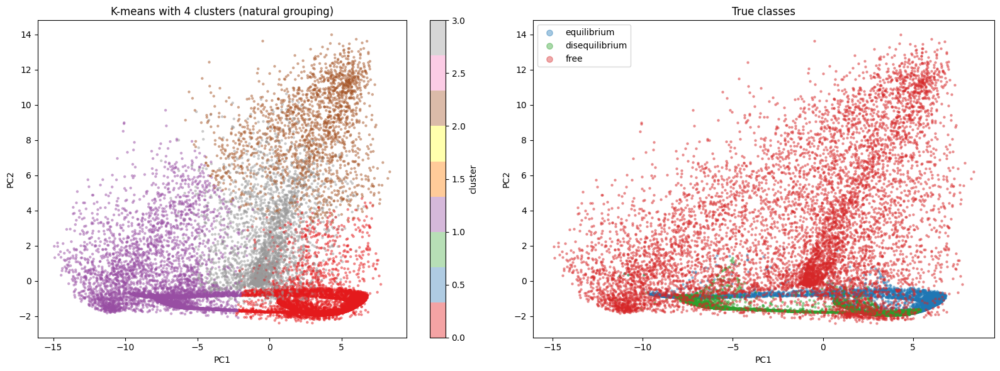

In [42]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# cluster the full data into 4
km4 = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters4 = km4.fit_predict(X_pca_A[:, :6])
print("4-cluster sizes:", np.bincount(clusters4))

# plot: 4-clusters next to true classes
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc = axes[0].scatter(X_pca_A[:, 0], X_pca_A[:, 1], c=clusters4, cmap="Set1", s=5, alpha=0.4)
axes[0].set_title("K-means with 4 clusters (natural grouping)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
plt.colorbar(sc, ax=axes[0], label="cluster")

colors = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}
names = {0: "equilibrium", 1: "disequilibrium", 2: "free"}
for cls in [0, 1, 2]:
    m = labels == cls
    axes[1].scatter(X_pca_A[m, 0], X_pca_A[m, 1], s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[1].set_title("True classes")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].legend(markerscale=3)

plt.tight_layout()
plt.show()

In [43]:
!pip install hdbscan -q

In [44]:
import hdbscan
clusterer = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=10)
hdb_labels = clusterer.fit_predict(X_pca_A[:, :6])
n_clusters_found = len(set(hdb_labels)) - (1 if -1 in hdb_labels else 0)
n_noise = np.sum(hdb_labels == -1)

print("Clusters HDBSCAN found:", n_clusters_found)
print("Points labeled as noise:", n_noise)
print("Cluster sizes:", np.bincount(hdb_labels[hdb_labels >= 0]))

Clusters HDBSCAN found: 5
Points labeled as noise: 7835
Cluster sizes: [  746   865   665 12103  3064]


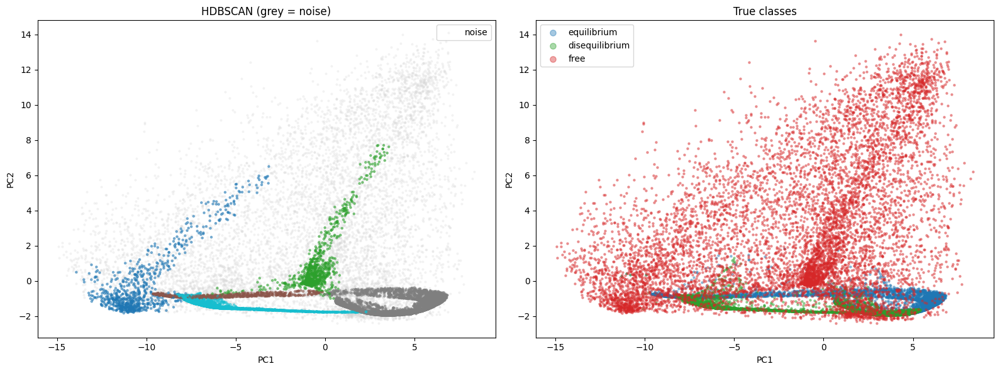

In [45]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# left: HDBSCAN clusters (noise = grey)
noise_mask = hdb_labels == -1
axes[0].scatter(X_pca_A[noise_mask, 0], X_pca_A[noise_mask, 1],
                s=4, alpha=0.2, color="lightgrey", label="noise")
sc = axes[0].scatter(X_pca_A[~noise_mask, 0], X_pca_A[~noise_mask, 1],
                     c=hdb_labels[~noise_mask], cmap="tab10", s=5, alpha=0.5)
axes[0].set_title("HDBSCAN (grey = noise)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[0].legend()

# right: true classes
colors = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}
names = {0: "equilibrium", 1: "disequilibrium", 2: "free"}
for cls in [0, 1, 2]:
    m = labels == cls
    axes[1].scatter(X_pca_A[m, 0], X_pca_A[m, 1], s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[1].set_title("True classes")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].legend(markerscale=3)

plt.tight_layout()
plt.show()

In [46]:
!pip install umap-learn -q

In [47]:
import umap

reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42)
X_umap = reducer.fit_transform(X_scaled)

print("UMAP output shape:", X_umap.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



UMAP output shape: (25278, 2)


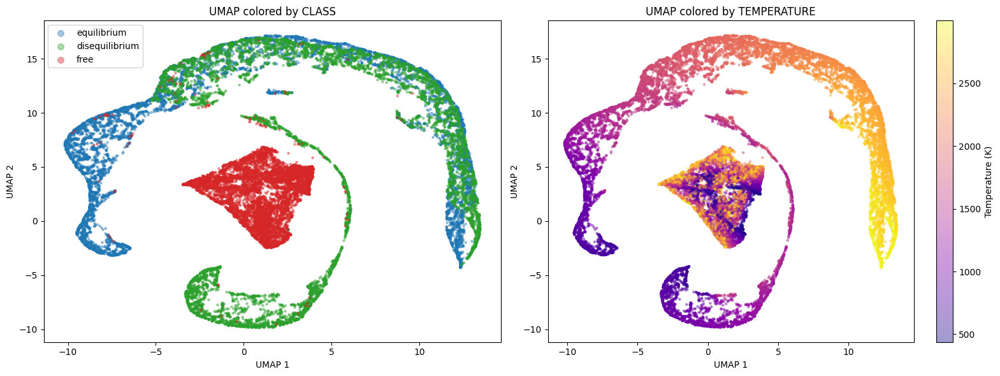

In [48]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# left: colored by true class
colors = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}
names = {0: "equilibrium", 1: "disequilibrium", 2: "free"}
for cls in [0, 1, 2]:
    m = labels == cls
    axes[0].scatter(X_umap[m, 0], X_umap[m, 1], s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[0].set_title("UMAP colored by CLASS")
axes[0].set_xlabel("UMAP 1"); axes[0].set_ylabel("UMAP 2")
axes[0].legend(markerscale=3)

# right: colored by temperature
sc = axes[1].scatter(X_umap[:, 0], X_umap[:, 1], c=T, cmap="plasma", s=5, alpha=0.4)
axes[1].set_title("UMAP colored by TEMPERATURE")
axes[1].set_xlabel("UMAP 1"); axes[1].set_ylabel("UMAP 2")
plt.colorbar(sc, ax=axes[1], label="Temperature (K)")

plt.tight_layout()
plt.savefig("umap_class_temp.png", dpi=150)
plt.show()

In [49]:
reducer_3d = umap.UMAP(n_components=3, n_neighbors=30, min_dist=0.1, random_state=42)
X_umap3 = reducer_3d.fit_transform(X_scaled)

print("X_umap3 shape:", X_umap3.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



X_umap3 shape: (25278, 3)


In [50]:
import plotly.express as px
import pandas as pd

df3 = pd.DataFrame({
    "UMAP1": X_umap3[:, 0],
    "UMAP2": X_umap3[:, 1],
    "UMAP3": X_umap3[:, 2],
    "class": [ {0:"equilibrium",1:"disequilibrium",2:"free"}[l] for l in labels ]
})

fig = px.scatter_3d(df3, x="UMAP1", y="UMAP2", z="UMAP3",
                    color="class",
                    color_discrete_map={"equilibrium":"blue",
                                        "disequilibrium":"green",
                                        "free":"red"},
                    opacity=0.4,
                    title="3D UMAP colored by class")
fig.update_traces(marker=dict(size=2))
fig.show()

In [51]:
df3["temperature"] = T

fig = px.scatter_3d(df3, x="UMAP1", y="UMAP2", z="UMAP3",
                    color="temperature",
                    color_continuous_scale="plasma",
                    opacity=0.4,
                    title="3D UMAP colored by temperature")
fig.update_traces(marker=dict(size=2))
fig.show()

In [52]:
import hdbscan
import numpy as np

clusterer_umap = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=10)
umap_hdb_labels = clusterer_umap.fit_predict(X_umap3)

n_clusters = len(set(umap_hdb_labels)) - (1 if -1 in umap_hdb_labels else 0)
n_noise = np.sum(umap_hdb_labels == -1)

print("Clusters found:", n_clusters)
print("Noise points:", n_noise)
print("Cluster sizes:", np.bincount(umap_hdb_labels[umap_hdb_labels >= 0]))

Clusters found: 3
Noise points: 0
Cluster sizes: [ 8320  3536 13422]


In [53]:
from sklearn.metrics import adjusted_rand_score, confusion_matrix

ari = adjusted_rand_score(labels, umap_hdb_labels)
print("ARI (UMAP-HDBSCAN vs true classes):", ari)

cm = confusion_matrix(labels, umap_hdb_labels) if -1 not in umap_hdb_labels else None
# handle noise: show crosstab including noise
import pandas as pd
print(pd.crosstab(pd.Series(labels, name="true"),
                  pd.Series(umap_hdb_labels, name="cluster")))

ARI (UMAP-HDBSCAN vs true classes): 0.593109411666922
cluster     0     1     2
true                     
0           4     0  8422
1          11  3490  4925
2        8305    46    75


In [54]:
import plotly.express as px
import pandas as pd

df_hdb = pd.DataFrame({
    "UMAP1": X_umap3[:, 0],
    "UMAP2": X_umap3[:, 1],
    "UMAP3": X_umap3[:, 2],
    "cluster": umap_hdb_labels.astype(str)   # as string so colors are discrete
})

fig = px.scatter_3d(df_hdb, x="UMAP1", y="UMAP2", z="UMAP3",
                    color="cluster",
                    opacity=0.4,
                    title="3D UMAP colored by HDBSCAN cluster")
fig.update_traces(marker=dict(size=2))
fig.show()

### kernel PCA

In [55]:
import numpy as np

rng = np.random.default_rng(42)
n_per_class = 8000

idx_list = []
for c in [0, 1, 2]:
    class_idx = np.where(labels == c)[0]
    picked = rng.choice(class_idx, n_per_class, replace=False)
    idx_list.append(picked)

sub_idx = np.concatenate(idx_list)
rng.shuffle(sub_idx)


X_sub = X_scaled[sub_idx]
labels_sub = labels[sub_idx]
T_sub = T[sub_idx]

print("X_sub:", X_sub.shape)
print("Class balance:", np.bincount(labels_sub))

X_sub: (24000, 52)
Class balance: [8000 8000 8000]


In [56]:
from sklearn.decomposition import KernelPCA

kpca = KernelPCA(n_components=3, kernel="rbf", gamma=1/52, random_state=42)
X_kpca = kpca.fit_transform(X_sub)

print("X_kpca shape:", X_kpca.shape)

X_kpca shape: (24000, 3)


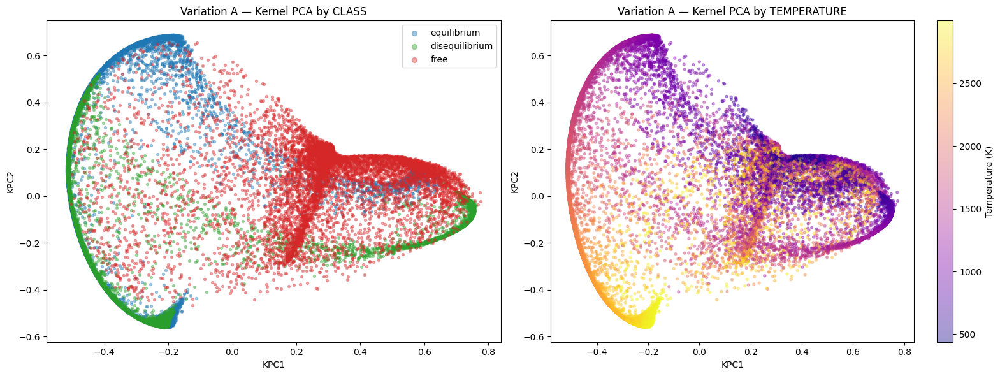

In [57]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = {0:"tab:blue",1:"tab:green",2:"tab:red"}
names = {0:"equilibrium",1:"disequilibrium",2:"free"}
for c in [0,1,2]:
    m = labels_sub == c
    axes[0].scatter(X_kpca[m,0], X_kpca[m,1], s=8, alpha=0.4, color=colors[c], label=names[c])
axes[0].set_title("Variation A — Kernel PCA by CLASS")
axes[0].set_xlabel("KPC1"); axes[0].set_ylabel("KPC2"); axes[0].legend(markerscale=2)

sc = axes[1].scatter(X_kpca[:,0], X_kpca[:,1], c=T_sub, cmap="plasma", s=8, alpha=0.4)
axes[1].set_title("Variation A — Kernel PCA by TEMPERATURE")
axes[1].set_xlabel("KPC1"); axes[1].set_ylabel("KPC2")
plt.colorbar(sc, ax=axes[1], label="Temperature (K)")
plt.tight_layout(); plt.savefig("kpca_varA.png", dpi=150); plt.show()

In [58]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, confusion_matrix
import pandas as pd

clusters_kpca = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(X_kpca)
ari = adjusted_rand_score(labels_sub, clusters_kpca)
print("Kernel PCA + K-means ARI:", ari)
print("(compare: linear PCA 0.13, UMAP 0.59)")
print(pd.crosstab(pd.Series(labels_sub, name="true"), pd.Series(clusters_kpca, name="cluster")))

Kernel PCA + K-means ARI: 0.2854954648550739
(compare: linear PCA 0.13, UMAP 0.59)
cluster     0     1     2     3
true                           
0         209   677  4092  3022
1           5  2916  1920  3159
2        5594  1600   405   401


In [59]:
import hdbscan
import numpy as np
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# HDBSCAN on the 3 Kernel PCA components
clusterer_kpca = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=5)
hdb_kpca = clusterer_kpca.fit_predict(X_kpca)

n_clusters = len(set(hdb_kpca)) - (1 if -1 in hdb_kpca else 0)
n_noise = np.sum(hdb_kpca == -1)

print("Clusters found:", n_clusters)
print("Noise points:", n_noise)
print("Cluster sizes:", np.bincount(hdb_kpca[hdb_kpca >= 0]))
print()
print("ARI (KPCA + HDBSCAN):", adjusted_rand_score(labels_sub, hdb_kpca))
print("(compare: linear PCA+Kmeans 0.13, UMAP+HDBSCAN 0.59)")
print()
print(pd.crosstab(pd.Series(labels_sub, name="true"), pd.Series(hdb_kpca, name="cluster")))

Clusters found: 3
Noise points: 3715
Cluster sizes: [11674  5802  2809]

ARI (KPCA + HDBSCAN): 0.377805095338066
(compare: linear PCA+Kmeans 0.13, UMAP+HDBSCAN 0.59)

cluster    -1     0     1     2
true                           
0         418  6902   680     0
1         502  4685    14  2799
2        2795    87  5108    10


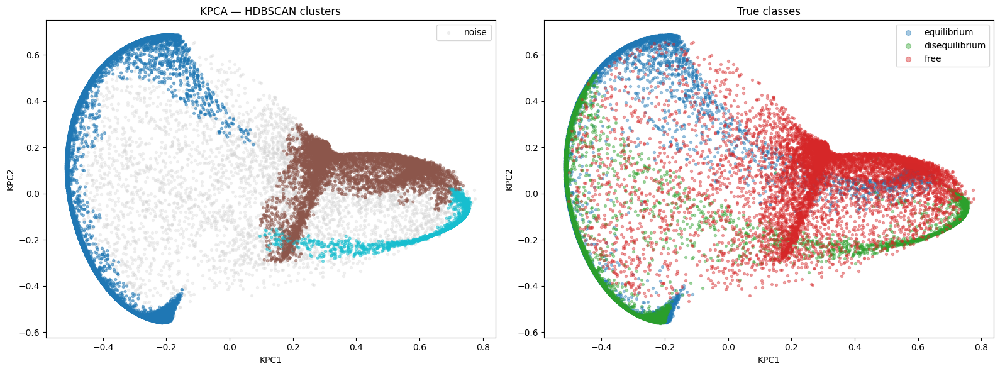

In [60]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# left: HDBSCAN clusters (noise grey)
noise = hdb_kpca == -1
axes[0].scatter(X_kpca[noise,0], X_kpca[noise,1], s=8, alpha=0.3, color="lightgrey", label="noise")
axes[0].scatter(X_kpca[~noise,0], X_kpca[~noise,1], c=hdb_kpca[~noise], cmap="tab10", s=8, alpha=0.5)
axes[0].set_title("KPCA — HDBSCAN clusters"); axes[0].legend()
axes[0].set_xlabel("KPC1"); axes[0].set_ylabel("KPC2")

# right: true classes
colors = {0:"tab:blue",1:"tab:green",2:"tab:red"}
names = {0:"equilibrium",1:"disequilibrium",2:"free"}
for c in [0,1,2]:
    m = labels_sub == c
    axes[1].scatter(X_kpca[m,0], X_kpca[m,1], s=8, alpha=0.4, color=colors[c], label=names[c])
axes[1].set_title("True classes"); axes[1].legend(markerscale=2)
axes[1].set_xlabel("KPC1"); axes[1].set_ylabel("KPC2")

plt.tight_layout(); plt.savefig("kpca_hdbscan.png", dpi=150); plt.show()

In [81]:
import plotly.express as px
import pandas as pd

names = {0:"equilibrium",1:"disequilibrium",2:"free"}

df_kA = pd.DataFrame({
    "KPC1": X_kpca[:,0], "KPC2": X_kpca[:,1], "KPC3": X_kpca[:,2],
    "class": [names[l] for l in labels_sub],
    "temperature": T_sub
})

fig = px.scatter_3d(df_kA, x="KPC1", y="KPC2", z="KPC3", color="class",
                    color_discrete_map={"equilibrium":"blue","disequilibrium":"green","free":"red"},
                    opacity=0.4, title="Variation A — 3D Kernel PCA by CLASS")
fig.update_traces(marker=dict(size=2)); fig.show()

In [84]:
fig = px.scatter_3d(df_kA, x="KPC1", y="KPC2", z="KPC3", color="temperature",
                    color_continuous_scale="plasma",
                    opacity=0.4, title="Variation A — 3D Kernel PCA by TEMPERATURE")
fig.update_traces(marker=dict(size=2)); fig.show()

In [61]:
from sklearn.decomposition import KernelPCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# a handful of gamma values across orders of magnitude
for g in [0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.5]:
    kpca = KernelPCA(n_components=3, kernel="rbf", gamma=g, random_state=42)
    Xk = kpca.fit_transform(X_sub)
    cl = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(Xk)
    ari = adjusted_rand_score(labels_sub, cl)
    print(f"gamma={g:.3f}  ARI={ari:.3f}")

gamma=0.001  ARI=0.143
gamma=0.005  ARI=0.261
gamma=0.010  ARI=0.282
gamma=0.020  ARI=0.237
gamma=0.050  ARI=0.222
gamma=0.100  ARI=0.168
gamma=0.500  ARI=0.123


# Variation B - No scaling

In [62]:
from sklearn.decomposition import PCA
import numpy as np

pca_B = PCA(n_components=7)
X_pca_B = pca_B.fit_transform(X_zscore)

print("Explained variance:", pca_B.explained_variance_ratio_)
print("Cumulative:")
for k in range(7):
    print(f"  {k+1}: {pca_B.explained_variance_ratio_[:k+1].sum():.4f}")

Explained variance: [0.48479395 0.23307696 0.08385029 0.07680181 0.0346292  0.02514851
 0.02017872]
Cumulative:
  1: 0.4848
  2: 0.7179
  3: 0.8017
  4: 0.8785
  5: 0.9132
  6: 0.9383
  7: 0.9585


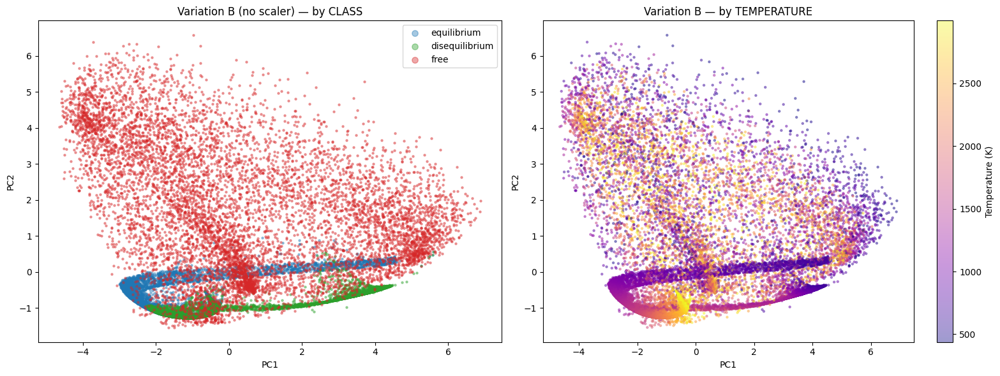

In [63]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = {0:"tab:blue",1:"tab:green",2:"tab:red"}
names = {0:"equilibrium",1:"disequilibrium",2:"free"}
for cls in [0,1,2]:
    m = labels == cls
    axes[0].scatter(X_pca_B[m,0], X_pca_B[m,1], s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[0].set_title("Variation B (no scaler) — by CLASS")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend(markerscale=3)

sc = axes[1].scatter(X_pca_B[:,0], X_pca_B[:,1], c=T, cmap="plasma", s=5, alpha=0.4)
axes[1].set_title("Variation B — by TEMPERATURE")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.colorbar(sc, ax=axes[1], label="Temperature (K)")
plt.tight_layout(); plt.savefig("varB_pca.png", dpi=150); plt.show()

In [64]:
import plotly.express as px
import pandas as pd

names = {0:"equilibrium",1:"disequilibrium",2:"free"}

df_pca_B = pd.DataFrame({
    "PC1": X_pca_B[:,0], "PC2": X_pca_B[:,1], "PC3": X_pca_B[:,2],
    "class": [names[l] for l in labels],
    "temperature": T
})

fig = px.scatter_3d(df_pca_B, x="PC1", y="PC2", z="PC3", color="class",
                    color_discrete_map={"equilibrium":"blue","disequilibrium":"green","free":"red"},
                    opacity=0.4, title="Variation B — 3D PCA by CLASS")
fig.update_traces(marker=dict(size=2)); fig.show()

In [65]:
fig = px.scatter_3d(df_pca_B, x="PC1", y="PC2", z="PC3", color="temperature",
                    color_continuous_scale="plasma",
                    opacity=0.4, title="Variation B — 3D PCA by TEMPERATURE")
fig.update_traces(marker=dict(size=2)); fig.show()

In [66]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, confusion_matrix
import pandas as pd

kmB = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_B = kmB.fit_predict(X_pca_B[:, :7])
print("Cluster sizes:", np.bincount(clusters_B))
print("ARI:", adjusted_rand_score(labels, clusters_B))
print(pd.crosstab(pd.Series(labels,name="true"), pd.Series(clusters_B,name="cluster")))

Cluster sizes: [ 3247 15458  6573]
ARI: 0.1591762562603966
cluster     0     1     2
true                     
0           0  7701   725
1           0  5414  3012
2        3247  2343  2836


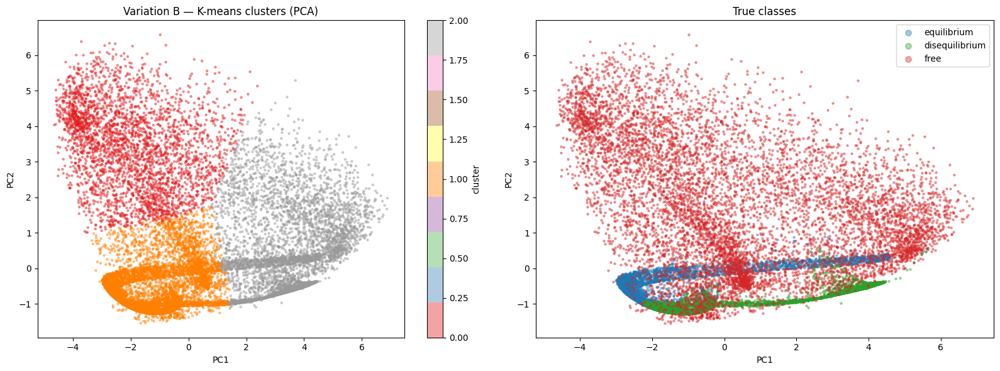

In [67]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc = axes[0].scatter(X_pca_B[:,0], X_pca_B[:,1], c=clusters_B, cmap="Set1", s=5, alpha=0.4)
axes[0].set_title("Variation B — K-means clusters (PCA)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
plt.colorbar(sc, ax=axes[0], label="cluster")

colors = {0:"tab:blue",1:"tab:green",2:"tab:red"}
names = {0:"equilibrium",1:"disequilibrium",2:"free"}
for cls in [0,1,2]:
    m = labels == cls
    axes[1].scatter(X_pca_B[m,0], X_pca_B[m,1], s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[1].set_title("True classes")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].legend(markerscale=3)
plt.tight_layout(); plt.savefig("varB_kmeans.png", dpi=150); plt.show()

In [68]:
from sklearn.metrics import silhouette_score
rng = np.random.default_rng(42)
sample = rng.choice(len(X_pca_B), 5000, replace=False)
print("k | silhouette (Variation B)")
for k in [2,3,4,5,6,7,8]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lb = km.fit_predict(X_pca_B[sample, :7])
    print(f"  {k}: {silhouette_score(X_pca_B[sample,:6], lb):.4f}")

k | silhouette (Variation B)
  2: 0.4581
  3: 0.4995
  4: 0.3856
  5: 0.4150
  6: 0.4053
  7: 0.4106
  8: 0.4210


In [69]:
import hdbscan
clB = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=10)
hdbB = clB.fit_predict(X_pca_B[:, :7])
nC = len(set(hdbB)) - (1 if -1 in hdbB else 0)
print("Clusters:", nC, "| Noise:", np.sum(hdbB==-1))
print("Sizes:", np.bincount(hdbB[hdbB>=0]))
print("ARI:", adjusted_rand_score(labels, hdbB))

Clusters: 6 | Noise: 7250
Sizes: [  814   287   798  3289   675 12165]
ARI: 0.4300283902459739


In [70]:
import umap

reducer_2d_B = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42)
X_umap_2d_B = reducer_2d_B.fit_transform(X_zscore)
print("UMAP 2D shape:", X_umap_2d_B.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



UMAP 2D shape: (25278, 2)


In [71]:
reducer_3d_B = umap.UMAP(n_components=3, n_neighbors=30, min_dist=0.1, random_state=42)
X_umap_3d_B = reducer_3d_B.fit_transform(X_zscore)
print("UMAP 3D shape:", X_umap_3d_B.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



UMAP 3D shape: (25278, 3)


In [72]:
import hdbscan
from sklearn.metrics import adjusted_rand_score
import pandas as pd
import numpy as np

# HDBSCAN on 2D UMAP
hdb_2d_B = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=10).fit_predict(X_umap_2d_B)
# HDBSCAN on 3D UMAP
hdb_3d_B = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=10).fit_predict(X_umap_3d_B)

print("=== 2D UMAP + HDBSCAN ===")
print("Clusters:", len(set(hdb_2d_B)) - (1 if -1 in hdb_2d_B else 0),
      "| Noise:", np.sum(hdb_2d_B == -1))
print("ARI:", adjusted_rand_score(labels, hdb_2d_B))
print()
print("=== 3D UMAP + HDBSCAN ===")
print("Clusters:", len(set(hdb_3d_B)) - (1 if -1 in hdb_3d_B else 0),
      "| Noise:", np.sum(hdb_3d_B == -1))
print("ARI:", adjusted_rand_score(labels, hdb_3d_B))

=== 2D UMAP + HDBSCAN ===
Clusters: 4 | Noise: 11
ARI: 0.5943209523073406

=== 3D UMAP + HDBSCAN ===
Clusters: 4 | Noise: 4
ARI: 0.5968325385189572


In [73]:
print("2D UMAP crosstab:")
print(pd.crosstab(pd.Series(labels, name="true"), pd.Series(hdb_2d_B, name="cluster")))
print("\n3D UMAP crosstab:")
print(pd.crosstab(pd.Series(labels, name="true"), pd.Series(hdb_3d_B, name="cluster")))

2D UMAP crosstab:
cluster  -1    0     1     2     3
true                              
0         0  126     4     0  8296
1         9   76    12  3482  4847
2         2    4  8334    54    32

3D UMAP crosstab:
cluster  -1     0    1     2     3
true                              
0         0  8295  127     0     4
1         0  4826   77  3511    12
2         4    32    4    34  8352


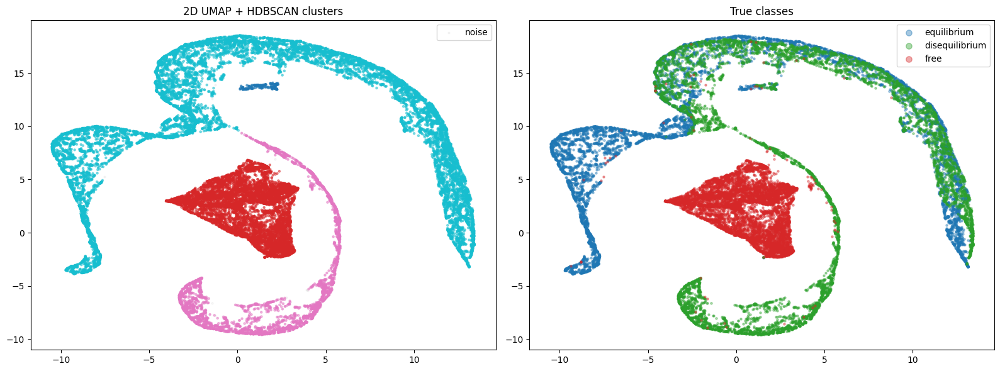

In [74]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
noise = hdb_2d_B == -1
axes[0].scatter(X_umap_2d_B[noise,0], X_umap_2d_B[noise,1], s=4, alpha=0.2, color="lightgrey", label="noise")
axes[0].scatter(X_umap_2d_B[~noise,0], X_umap_2d_B[~noise,1], c=hdb_2d_B[~noise], cmap="tab10", s=5, alpha=0.5)
axes[0].set_title("2D UMAP + HDBSCAN clusters"); axes[0].legend()

colors = {0:"tab:blue",1:"tab:green",2:"tab:red"}
names = {0:"equilibrium",1:"disequilibrium",2:"free"}
for cls in [0,1,2]:
    m = labels == cls
    axes[1].scatter(X_umap_2d_B[m,0], X_umap_2d_B[m,1], s=5, alpha=0.4, color=colors[cls], label=names[cls])
axes[1].set_title("True classes"); axes[1].legend(markerscale=3)
plt.tight_layout(); plt.show()

In [75]:
import plotly.express as px
import pandas as pd

df_hdb3d = pd.DataFrame({
    "U1": X_umap_3d_B[:, 0],
    "U2": X_umap_3d_B[:, 1],
    "U3": X_umap_3d_B[:, 2],
    "cluster": hdb_3d_B.astype(str)
})

fig = px.scatter_3d(df_hdb3d, x="U1", y="U2", z="U3",
                    color="cluster",
                    opacity=0.4,
                    title="Variation B — 3D UMAP by HDBSCAN cluster")
fig.update_traces(marker=dict(size=2))
fig.show()

In [76]:
import numpy as np

rng = np.random.default_rng(42)
n_per_class = 8000

idx_list = []
for c in [0, 1, 2]:
    class_idx = np.where(labels == c)[0]
    picked = rng.choice(class_idx, n_per_class, replace=False)
    idx_list.append(picked)

sub_idx = np.concatenate(idx_list)
rng.shuffle(sub_idx)

X_sub_B = X_zscore[sub_idx]
labels_sub_B = labels[sub_idx]
T_sub_B = T_all[sub_idx]

print("X_sub_B:", X_sub_B.shape)
print("Class balance:", np.bincount(labels_sub_B))

X_sub_B: (24000, 52)
Class balance: [8000 8000 8000]


In [77]:
from sklearn.decomposition import KernelPCA

kpca_B = KernelPCA(n_components=3, kernel="rbf", gamma=1/52, random_state=42)
X_kpca_B = kpca_B.fit_transform(X_sub_B)
print("X_kpca_B shape:", X_kpca_B.shape)

X_kpca_B shape: (24000, 3)


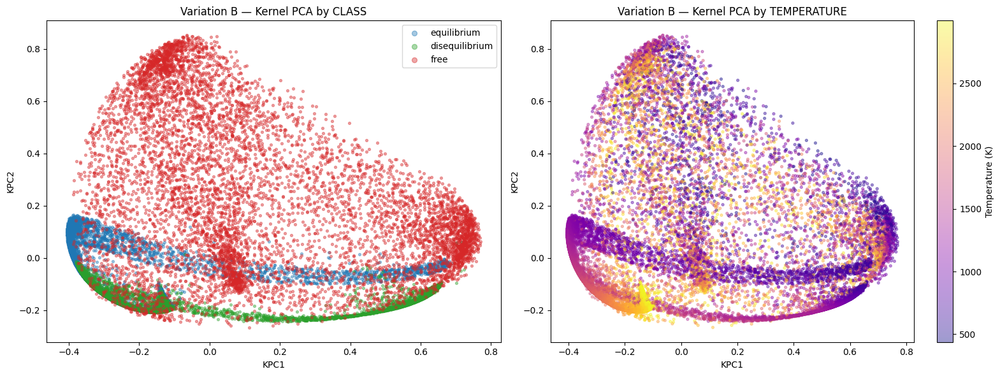

In [78]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = {0:"tab:blue",1:"tab:green",2:"tab:red"}
names = {0:"equilibrium",1:"disequilibrium",2:"free"}

for c in [0,1,2]:
    m = labels_sub_B == c
    axes[0].scatter(X_kpca_B[m,0], X_kpca_B[m,1], s=8, alpha=0.4, color=colors[c], label=names[c])
axes[0].set_title("Variation B — Kernel PCA by CLASS")
axes[0].set_xlabel("KPC1"); axes[0].set_ylabel("KPC2"); axes[0].legend(markerscale=2)

sc = axes[1].scatter(X_kpca_B[:,0], X_kpca_B[:,1], c=T_sub_B, cmap="plasma", s=8, alpha=0.4)
axes[1].set_title("Variation B — Kernel PCA by TEMPERATURE")
axes[1].set_xlabel("KPC1"); axes[1].set_ylabel("KPC2")
plt.colorbar(sc, ax=axes[1], label="Temperature (K)")
plt.tight_layout(); plt.savefig("kpca_varB.png", dpi=150); plt.show()

In [82]:
df_kB = pd.DataFrame({
    "KPC1": X_kpca_B[:,0], "KPC2": X_kpca_B[:,1], "KPC3": X_kpca_B[:,2],
    "class": [names[l] for l in labels_sub_B],
    "temperature": T_sub_B
})

fig = px.scatter_3d(df_kB, x="KPC1", y="KPC2", z="KPC3", color="class",
                    color_discrete_map={"equilibrium":"blue","disequilibrium":"green","free":"red"},
                    opacity=0.4, title="Variation B — 3D Kernel PCA by CLASS")
fig.update_traces(marker=dict(size=2)); fig.show()

In [83]:
fig = px.scatter_3d(df_kB, x="KPC1", y="KPC2", z="KPC3", color="temperature",
                    color_continuous_scale="plasma",
                    opacity=0.4, title="Variation B — 3D Kernel PCA by TEMPERATURE")
fig.update_traces(marker=dict(size=2)); fig.show()

In [79]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

clusters_kpca_B = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_kpca_B)
print("Variation B — Kernel PCA + K-means ARI:", adjusted_rand_score(labels_sub_B, clusters_kpca_B))
print("(compare: A's KPCA+Kmeans 0.285)")
print(pd.crosstab(pd.Series(labels_sub_B, name="true"), pd.Series(clusters_kpca_B, name="cluster")))

Variation B — Kernel PCA + K-means ARI: 0.18906400350073782
(compare: A's KPCA+Kmeans 0.285)
cluster     0     1     2
true                     
0         694  7306     0
1        2876  5124     0
2        2625  1853  3522


In [85]:
import hdbscan

hdb_kpca_B = hdbscan.HDBSCAN(min_cluster_size=200, min_samples=5).fit_predict(X_kpca_B)
nC = len(set(hdb_kpca_B)) - (1 if -1 in hdb_kpca_B else 0)
print("Clusters:", nC, "| Noise:", np.sum(hdb_kpca_B == -1))
print("Sizes:", np.bincount(hdb_kpca_B[hdb_kpca_B >= 0]))
print("Variation B — KPCA + HDBSCAN ARI:", adjusted_rand_score(labels_sub_B, hdb_kpca_B))
print("(compare: A's KPCA+HDBSCAN 0.378)")
print(pd.crosstab(pd.Series(labels_sub_B, name="true"), pd.Series(hdb_kpca_B, name="cluster")))

Clusters: 6 | Noise: 4262
Sizes: [ 1373  1007  1617   731  3138 11872]
Variation B — KPCA + HDBSCAN ARI: 0.35623247102412636
(compare: A's KPCA+HDBSCAN 0.378)
cluster    -1     0     1     2    3     4     5
true                                            
0         238     0     0     0  713     0  7049
1         144     0     0     3    8  3111  4734
2        3880  1373  1007  1614   10    27    89
